# Chapitre 17 - Exercices 17.1 à 17.6

Ces exercices portent sur les propriétés de Markov des graphes (17.1, 17.2), sur
l'indépendance conditionnelle (17.4) et sur l'algèbre de la matrice de précision du
modèle gaussien (17.3, 17.5, 17.6). Chaque résultat théorique est vérifié
numériquement.

In [1]:
from itertools import combinations

import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import ch17_graphes as g

## Exercice 17.1 : Indépendances et cliques du graphe de la figure 17.8

**Énoncé.** Pour le graphe de Markov de la figure 17.8 (sommets $X_1, \dots, X_6$),
donner toutes les relations d'indépendance conditionnelle qu'il implique et trouver ses
cliques maximales.

Les arêtes de la figure 17.8 sont : $X_1 - X_2$, $X_1 - X_4$, $X_1 - X_6$, $X_2 - X_6$,
$X_3 - X_4$ et $X_5 - X_6$.

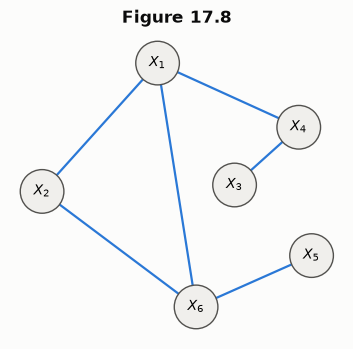

In [2]:
p = 6
aretes = [(0, 1), (0, 3), (0, 5), (1, 5), (2, 3), (4, 5)]
A = g.adjacency_from_edges(p, aretes)
pos = np.array([[0.0, 1.0], [-0.9, 0.0], [0.6, 0.05], [1.1, 0.5], [1.2, -0.5], [0.3, -0.9]])
fig, ax = plt.subplots(figsize=(4.5, 4))
g.draw_graph(A, pos=pos, ax=ax, node_size=0.17, title="Figure 17.8")
plt.show()

**Rappels.** (i) Propriété de Markov **par paires** : si $j \not\sim k$, alors
$X_j \perp X_k \mid$ reste (éq. (17.1)). (ii) Propriété de Markov **globale** : si
$C$ sépare $A$ et $B$ (tout chemin de $A$ à $B$ passe par $C$), alors
$X_A \perp X_B \mid X_C$ (éq. (17.2)). Pour une loi positive, (i) et (ii) sont
équivalentes, donc « toutes les relations impliquées » sont celles données par la
séparation.

**1. Relations par paires.** Il y a $\binom62 = 15$ paires et 6 arêtes, donc 9 paires
non adjacentes, chacune donnant une indépendance sachant les 4 autres variables :

In [3]:
nom = lambda S: "{" + ", ".join("X%d" % (v + 1) for v in sorted(S)) + "}"
paires_absentes = [(j, k) for j, k in combinations(range(p), 2) if not A[j, k]]
for j, k in paires_absentes:
    reste = [v for v in range(p) if v not in (j, k)]
    print("X%d ⊥ X%d | %s" % (j + 1, k + 1, nom(reste)))

X1 ⊥ X3 | {X2, X4, X5, X6}
X1 ⊥ X5 | {X2, X3, X4, X6}
X2 ⊥ X3 | {X1, X4, X5, X6}
X2 ⊥ X4 | {X1, X3, X5, X6}
X2 ⊥ X5 | {X1, X3, X4, X6}
X3 ⊥ X5 | {X1, X2, X4, X6}
X3 ⊥ X6 | {X1, X2, X4, X5}
X4 ⊥ X5 | {X1, X2, X3, X6}
X4 ⊥ X6 | {X1, X2, X3, X5}


**2. Propriété de Markov locale.** L'ensemble des voisins $\mathcal N(j)$ sépare $j$ de
tous les sommets non voisins (tout chemin partant de $j$ passe d'abord par un voisin).
D'où, pour chaque sommet, $X_j \perp X_{\text{non-voisins}} \mid X_{\mathcal N(j)}$ :

In [4]:
for j in range(p):
    voisins = set(np.flatnonzero(A[j]))
    autres = set(range(p)) - voisins - {j}
    if autres:
        assert g.separates(A, [j], autres, voisins)
        print("X%d ⊥ %s | %s" % (j + 1, nom(autres), nom(voisins)))

X1 ⊥ {X3, X5} | {X2, X4, X6}
X2 ⊥ {X3, X4, X5} | {X1, X6}
X3 ⊥ {X1, X2, X5, X6} | {X4}
X4 ⊥ {X2, X5, X6} | {X1, X3}
X5 ⊥ {X1, X2, X3, X4} | {X6}
X6 ⊥ {X3, X4} | {X1, X2, X5}


**3. Séparations par des sommets d'articulation.** Le graphe a la forme d'un triangle
$\{X_1, X_2, X_6\}$ auquel sont accrochées deux « branches » : $X_1 - X_4 - X_3$ et
$X_6 - X_5$. Ainsi :

- $X_1$ sépare $\{X_3, X_4\}$ de $\{X_2, X_5, X_6\}$ ;
- $X_4$ sépare $X_3$ de $\{X_1, X_2, X_5, X_6\}$ ;
- $X_6$ sépare $X_5$ de $\{X_1, X_2, X_3, X_4\}$ ;
- $\{X_1, X_6\}$ sépare $X_2$ de $\{X_3, X_4, X_5\}$ (voisins de $X_2$).

Toute autre relation s'obtient en restreignant ces ensembles ou en agrandissant le
séparateur. Pour une liste exhaustive et compacte, énumérons, pour chaque paire non
adjacente, ses **séparateurs minimaux**.

In [5]:
def separateurs_minimaux(A, a, b):
    autres = [v for v in range(A.shape[0]) if v not in (a, b)]
    seps = [set(C) for r in range(len(autres) + 1) for C in combinations(autres, r)
            if g.separates(A, [a], [b], C)]
    return [C for C in seps if not any(D < C for D in seps)]


for j, k in paires_absentes:
    seps = separateurs_minimaux(A, j, k)
    print("X%d ⊥ X%d | " % (j + 1, k + 1) + "  ou  ".join(nom(C) for C in seps))

X1 ⊥ X3 | {X4}
X1 ⊥ X5 | {X6}
X2 ⊥ X3 | {X1}  ou  {X4}
X2 ⊥ X4 | {X1}
X2 ⊥ X5 | {X6}
X3 ⊥ X5 | {X1}  ou  {X4}  ou  {X6}
X3 ⊥ X6 | {X1}  ou  {X4}
X4 ⊥ X5 | {X1}  ou  {X6}
X4 ⊥ X6 | {X1}


Par exemple $X_3 \perp X_5 \mid X_4$, mais aussi $X_3 \perp X_5 \mid X_1$ et
$X_3 \perp X_5 \mid X_6$ : tout chemin de $X_3$ à $X_5$ passe par $X_4$, $X_1$ et $X_6$, donc chacun
de ces sommets suffit à les séparer. Et par la propriété globale, tout ensemble **contenant** un
séparateur et ne contenant pas $j, k$ sépare encore (par ex. $X_3 \perp X_5 \mid \{X_1, X_2\}$).

**4. Cliques maximales.** Le seul triangle est $\{X_1, X_2, X_6\}$ ; les autres arêtes
ne sont contenues dans aucun triangle.

In [6]:
print("cliques maximales :", [nom(c) for c in g.maximal_cliques(A)])

cliques maximales : ['{X1, X2, X6}', '{X1, X4}', '{X3, X4}', '{X5, X6}']


D'après Hammersley–Clifford, toute densité positive markovienne pour ce graphe s'écrit
$f(x) = \psi_{126}(x_1,x_2,x_6)\,\psi_{14}(x_1,x_4)\,\psi_{34}(x_3,x_4)\,\psi_{56}(x_5,x_6)/Z$.

**Vérification numérique.** On simule un vecteur gaussien de matrice de précision à
support sur ce graphe et on calcule quelques corrélations partielles empiriques
(corrélation des résidus après régression sur l'ensemble conditionnant).

In [7]:
rng = np.random.RandomState(0)
Theta = g.make_sparse_precision(A, rng)
X = rng.randn(30000, p) @ np.linalg.cholesky(np.linalg.inv(Theta)).T


def corr_partielle(X, j, k, C):
    Z = np.c_[np.ones(len(X)), X[:, list(C)]]
    rj = X[:, j] - Z @ np.linalg.lstsq(Z, X[:, j], rcond=None)[0]
    rk = X[:, k] - Z @ np.linalg.lstsq(Z, X[:, k], rcond=None)[0]
    return np.corrcoef(rj, rk)[0, 1]


tests = [(2, 4, [3]), (2, 4, [0]), (2, 4, [5]), (1, 3, [0]), (1, 4, [5]), (1, 2, [0, 5]),
         (2, 4, []), (1, 3, []), (1, 3, [5])]
for j, k, C in tests:
    sep = g.separates(A, [j], [k], C)
    print("corr(X%d, X%d | %-12s) = %+.3f   séparés : %s"
          % (j + 1, k + 1, nom(C), corr_partielle(X, j, k, C), sep))

corr(X3, X5 | {X4}        ) = +0.001   séparés : True
corr(X3, X5 | {X1}        ) = -0.003   séparés : True
corr(X3, X5 | {X6}        ) = -0.003   séparés : True
corr(X2, X4 | {X1}        ) = -0.003   séparés : True
corr(X2, X5 | {X6}        ) = -0.001   séparés : True
corr(X2, X3 | {X1, X6}    ) = -0.001   séparés : True
corr(X3, X5 | {}          ) = +0.054   séparés : False
corr(X2, X4 | {}          ) = +0.397   séparés : False
corr(X2, X4 | {X6}        ) = +0.194   séparés : False


Les corrélations partielles sont nulles (à $\pm 0{,}01$ près, l'erreur d'échantillonnage)
exactement quand l'ensemble conditionnant sépare les deux sommets.

> **À retenir.** Toutes les indépendances conditionnelles d'un graphe de Markov se
> lisent par **séparation** ; il suffit de lister, pour chaque paire non adjacente, les
> séparateurs minimaux. Ici : 9 paires non adjacentes, et les cliques maximales sont
> $\{X_1,X_2,X_6\}$, $\{X_1,X_4\}$, $\{X_3,X_4\}$, $\{X_5,X_6\}$.

## Exercice 17.2 : Construire un graphe à partir d'indépendances

**Énoncé.** Pour quatre variables $X_1, \dots, X_4$, dessiner un graphe ayant les
relations d'indépendance suivantes :

(a) $X_1 \perp X_3 \mid X_2$ et $X_2 \perp X_4 \mid X_3$ ;
(b) $X_1 \perp X_4 \mid X_2, X_3$ et $X_2 \perp X_4 \mid X_1, X_3$ ;
(c) $X_1 \perp X_4 \mid X_2, X_3$, $X_1 \perp X_3 \mid X_2, X_4$ et $X_3 \perp X_4 \mid X_1, X_2$.

**Méthode.** On veut un graphe dont la propriété de Markov globale **implique** ces
relations : pour chaque relation $X_j \perp X_k \mid X_C$, l'ensemble $C$ doit séparer
$j$ et $k$. Le graphe vide convient toujours (trivialement) ; on cherche le graphe le
plus riche, c'est-à-dire avec le **plus d'arêtes**, qui impose le moins de contraintes
supplémentaires.

**(a)** $X_1 \perp X_3 \mid X_2$ interdit l'arête $1-3$, et $X_2 \perp X_4 \mid X_3$
interdit l'arête $2-4$. L'arête $1-4$ est aussi interdite : le chemin $1 - 4 - 3$
éviterait $X_2$. Les arêtes $1-2$, $2-3$, $3-4$ sont permises : la **chaîne**
$X_1 - X_2 - X_3 - X_4$ convient, et c'est le seul graphe maximal.

**(b)** Les deux relations conditionnent sur « le reste » : ce sont des relations par
paires, qui interdisent exactement les arêtes $1-4$ et $2-4$. Graphe : arêtes $1-2$,
$1-3$, $2-3$, $3-4$ (un triangle $\{1,2,3\}$ avec $X_4$ accroché à $X_3$). On vérifie que
$\{X_2, X_3\}$ sépare $X_1$ et $X_4$, et $\{X_1, X_3\}$ sépare $X_2$ et $X_4$ (le seul
voisin de $X_4$ est $X_3$).

**(c)** Trois relations par paires interdisant $1-4$, $1-3$ et $3-4$ : il reste les
arêtes $1-2$, $2-3$, $2-4$, une **étoile** centrée en $X_2$.

Vérifions par une recherche exhaustive : parmi les $2^6 = 64$ graphes sur 4 sommets,
on garde ceux dont la séparation implique les relations demandées, puis ceux qui ont
le plus d'arêtes.

In [8]:
toutes_paires = list(combinations(range(4), 2))
contraintes = {
    "(a)": [(0, 2, [1]), (1, 3, [2])],
    "(b)": [(0, 3, [1, 2]), (1, 3, [0, 2])],
    "(c)": [(0, 3, [1, 2]), (0, 2, [1, 3]), (2, 3, [0, 1])],
}
solutions = {}
for cas, rel in contraintes.items():
    ok = []
    for masque in range(64):
        E = [e for b, e in enumerate(toutes_paires) if masque >> b & 1]
        A_ = g.adjacency_from_edges(4, E)
        if all(g.separates(A_, [j], [k], C) for j, k, C in rel):
            ok.append(E)
    nmax = max(len(E) for E in ok)
    maximaux = [E for E in ok if len(E) == nmax]
    solutions[cas] = maximaux[0]
    print("%s : %2d graphes compatibles ; maximal(aux) : %s"
          % (cas, len(ok), [[(j + 1, k + 1) for j, k in E] for E in maximaux]))

(a) : 10 graphes compatibles ; maximal(aux) : [[(1, 2), (2, 3), (3, 4)]]
(b) : 16 graphes compatibles ; maximal(aux) : [[(1, 2), (1, 3), (2, 3), (3, 4)]]
(c) :  8 graphes compatibles ; maximal(aux) : [[(1, 2), (2, 3), (2, 4)]]


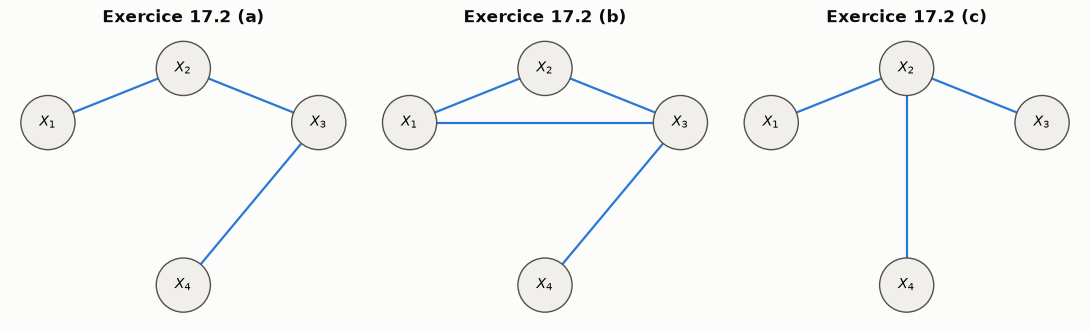

In [9]:
pos4 = np.array([[-1.0, 0.6], [0.0, 1.0], [1.0, 0.6], [0.0, -0.6]])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (cas, E) in zip(axes, solutions.items()):
    g.draw_graph(g.adjacency_from_edges(4, E), pos=pos4, ax=ax, node_size=0.2,
                 title="Exercice 17.2 %s" % cas)
plt.tight_layout()
plt.show()

Dans chaque cas le graphe maximal est unique. Vérification sur données gaussiennes
simulées selon ces graphes : les corrélations partielles demandées sont nulles.

In [10]:
rng = np.random.RandomState(1)
for cas, E in solutions.items():
    A_ = g.adjacency_from_edges(4, E)
    T_ = g.make_sparse_precision(A_, rng)
    X_ = rng.randn(30000, 4) @ np.linalg.cholesky(np.linalg.inv(T_)).T
    vals = ["corr(X%d,X%d|%s) = %+.3f" % (j + 1, k + 1, nom(C), corr_partielle(X_, j, k, C))
            for j, k, C in contraintes[cas]]
    print(cas, " ; ".join(vals))

(a) corr(X1,X3|{X2}) = -0.001 ; corr(X2,X4|{X3}) = -0.002
(b) corr(X1,X4|{X2, X3}) = +0.004 ; corr(X2,X4|{X1, X3}) = +0.000
(c) corr(X1,X4|{X2, X3}) = +0.005 ; corr(X1,X3|{X2, X4}) = +0.001 ; corr(X3,X4|{X1, X2}) = +0.006


> **À retenir.** Une relation qui conditionne sur **toutes** les autres variables
> supprime simplement une arête ; une relation qui conditionne sur **moins** de variables
> (cas (a)) impose en plus qu'aucun chemin ne contourne l'ensemble conditionnant, ce qui
> peut supprimer d'autres arêtes.

## Exercice 17.3 : Covariance partielle et matrice de précision

**Énoncé.** Soit $\Sigma$ la covariance de $X = (X_1, \dots, X_p)$ et $\Theta = \Sigma^{-1}$.
On partage $X$ en $X_a = (X_1, X_2)$ et $X_b$ (le reste), et on définit la **covariance
partielle** $\Sigma_{a.b} = \Sigma_{aa} - \Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}$ : c'est la
covariance de $X_a$ après ajustement linéaire sur $X_b$, et, dans le cas gaussien, la
covariance de la loi conditionnelle de $X_a$ sachant $X_b$. Le coefficient de corrélation
partielle $\rho_{12\mid\text{reste}}$ s'en déduit.

1. Montrer que $\Sigma_{a.b} = (\Theta_{aa})^{-1}$.
2. Montrer que si un coefficient hors diagonale de $\Theta$ est nul, la corrélation
   partielle correspondante est nulle.
3. Montrer que si $R = \operatorname{diag}(\Theta)^{-1/2}\,\Theta\,\operatorname{diag}(\Theta)^{-1/2}$
   (éq. (17.40)), alors $r_{jk} = -\rho_{jk\mid\text{reste}}$.

**1. Inverse par blocs.** Écrivons $\Sigma\Theta = I$ par blocs selon $(a, b)$ :

$$
\begin{aligned}
\Sigma_{aa}\Theta_{aa} + \Sigma_{ab}\Theta_{ba} &= I, \\
\Sigma_{ba}\Theta_{aa} + \Sigma_{bb}\Theta_{ba} &= 0 .
\end{aligned}
$$

$\Sigma_{bb}$ est inversible (sous-matrice principale d'une matrice définie positive), donc
la seconde ligne donne $\Theta_{ba} = -\Sigma_{bb}^{-1}\Sigma_{ba}\Theta_{aa}$. En reportant dans la
première :

$$
\big(\Sigma_{aa} - \Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}\big)\Theta_{aa} = I,
\quad\text{c'est-à-dire}\quad \Sigma_{a.b}\,\Theta_{aa} = I .
$$

Les deux matrices sont carrées $2\times2$, donc $\Sigma_{a.b} = (\Theta_{aa})^{-1}$. $\square$

**2. Corrélation partielle.** Par définition,
$\rho_{12\mid\text{reste}} = (\Sigma_{a.b})_{12}/\sqrt{(\Sigma_{a.b})_{11}(\Sigma_{a.b})_{22}}$.
L'inverse d'une matrice $2\times2$ s'écrit

$$
\Sigma_{a.b} = \begin{pmatrix}\theta_{11} & \theta_{12}\\ \theta_{12} & \theta_{22}\end{pmatrix}^{-1}
= \frac{1}{\theta_{11}\theta_{22} - \theta_{12}^2}\begin{pmatrix}\theta_{22} & -\theta_{12}\\ -\theta_{12} & \theta_{11}\end{pmatrix}.
$$

Le facteur commun (positif) se simplifie dans le quotient :

$$
\rho_{12\mid\text{reste}} = \frac{-\theta_{12}}{\sqrt{\theta_{22}\theta_{11}}} .
$$

Donc $\theta_{12} = 0 \Rightarrow \rho_{12\mid\text{reste}} = 0$. Pour une paire $(j,k)$
quelconque, on renumérote les variables pour placer $j, k$ en tête : si $P$ est la
matrice de permutation, la covariance devient $P\Sigma P^T$ et son inverse
$P\Theta P^T$, dont les coefficients sont ceux de $\Theta$ permutés. Le résultat vaut donc
pour tout $\theta_{jk}$. $\square$

**3.** $R = D^{-1/2}\Theta D^{-1/2}$ avec $D = \operatorname{diag}(\theta_{11}, \dots, \theta_{pp})$, donc
$r_{jk} = \theta_{jk}/\sqrt{\theta_{jj}\theta_{kk}}$, et d'après le point 2,
$r_{jk} = -\rho_{jk\mid\text{reste}}$. $\square$

> **Remarque.** Dans le cas gaussien, $\rho_{jk\mid\text{reste}} = 0$ équivaut à
> $X_j \perp X_k \mid$ reste (la loi conditionnelle de $(X_j, X_k)$ est gaussienne, et pour
> un couple gaussien, corrélation nulle équivaut à indépendance) : on retrouve que les
> zéros de $\Theta$ codent le graphe.

**Vérification numérique.** On compare, pour toutes les paires, la corrélation
partielle calculée par les résidus de régression et $-r_{jk}$ calculé sur
$\hat\Theta = S^{-1}$ ; puis on vérifie $\Sigma_{a.b} = (\Theta_{aa})^{-1}$.

In [11]:
rng = np.random.RandomState(2)
p3 = 6
M = rng.randn(p3, p3)
Sigma = M @ M.T + p3 * np.eye(p3)
X3 = rng.randn(5000, p3) @ np.linalg.cholesky(Sigma).T
S = g.empirical_covariance(X3)
Th = np.linalg.inv(S)
d = 1 / np.sqrt(np.diag(Th))
R = Th * np.outer(d, d)
rho_res, r_moins = [], []
for j, k in combinations(range(p3), 2):
    reste = [v for v in range(p3) if v not in (j, k)]
    rho_res.append(corr_partielle(X3, j, k, reste))
    r_moins.append(-R[j, k])
print("écart max |rho_résidus - (-r_jk)| = %.1e" % np.max(np.abs(np.array(rho_res) - r_moins)))
a, b = [0, 1], list(range(2, p3))
Sab = S[np.ix_(a, a)] - S[np.ix_(a, b)] @ np.linalg.solve(S[np.ix_(b, b)], S[np.ix_(b, a)])
print("écart max |Sigma_a.b - (Theta_aa)^-1| = %.1e" % np.abs(Sab - np.linalg.inv(Th[np.ix_(a, a)])).max())

écart max |rho_résidus - (-r_jk)| = 1.7e-16
écart max |Sigma_a.b - (Theta_aa)^-1| = 3.6e-15


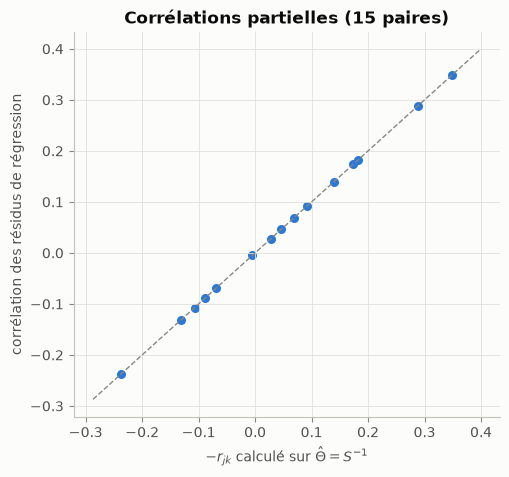

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(r_moins, rho_res, color=BLUE, s=30)
lim = [min(r_moins) - 0.05, max(r_moins) + 0.05]
ax.plot(lim, lim, color=GRAY, ls="--", lw=1)
ax.set(title="Corrélations partielles (15 paires)", xlabel=r"$-r_{jk}$ calculé sur $\hat\Theta = S^{-1}$",
       ylabel="corrélation des résidus de régression")
plt.show()

Les deux calculs coïncident à la précision machine (ce sont deux écritures exactes de la
même quantité empirique).

> **À retenir.** $\Sigma_{a.b} = (\Theta_{aa})^{-1}$ (complément de Schur) et
> $\rho_{jk\mid\text{reste}} = -\theta_{jk}/\sqrt{\theta_{jj}\theta_{kk}}$ : la matrice de
> précision normalisée donne directement (au signe près) toutes les corrélations
> partielles.

## Exercice 17.4 : Densité conditionnelle et indépendance conditionnelle

**Énoncé.** On note $f(X_1\mid X_2, \dots, X_p)$ la densité conditionnelle de $X_1$
sachant $X_2, \dots, X_p$. Montrer que si $f(X_1 \mid X_2, X_3, \dots, X_p) = f(X_1\mid X_3, \dots, X_p)$,
alors $X_1 \perp X_2 \mid X_3, \dots, X_p$.

**Rappel.** $X_1 \perp X_2 \mid Y$ (avec $Y = (X_3, \dots, X_p)$) signifie
$f(x_1, x_2 \mid y) = f(x_1\mid y)f(x_2\mid y)$ pour tout $y$ tel que $f(y) > 0$.

**Solution.** Notons $y = (x_3, \dots, x_p)$. Par définition des densités
conditionnelles, $f(x_1, x_2, y) = f(x_1\mid x_2, y)\,f(x_2, y)$. En divisant par $f(y) > 0$ :

$$
f(x_1, x_2 \mid y) = \frac{f(x_1, x_2, y)}{f(y)} = f(x_1\mid x_2, y)\,\frac{f(x_2, y)}{f(y)}
= f(x_1\mid x_2, y)\,f(x_2\mid y).
$$

Par hypothèse, $f(x_1\mid x_2, y) = f(x_1 \mid y)$, d'où

$$
f(x_1, x_2\mid y) = f(x_1\mid y)\,f(x_2\mid y),
$$

ce qui est exactement $X_1 \perp X_2 \mid Y$. $\square$

> **Remarque.** La réciproque est vraie aussi : si $f(x_1, x_2\mid y) = f(x_1\mid y)f(x_2\mid y)$,
> alors en divisant par $f(x_2\mid y)$ on obtient $f(x_1 \mid x_2, y) = f(x_1\mid y)$. Les deux
> formulations de l'indépendance conditionnelle sont donc équivalentes.

**Illustration numérique** (variables discrètes à 3 modalités) : on construit une loi
jointe $f(x_1, x_2, x_3) = f(x_3)\,f(x_2\mid x_3)\,f(x_1\mid x_3)$ où $X_1$ ne dépend que de
$X_3$, puis on vérifie les deux formulations.

In [13]:
rng = np.random.RandomState(3)
f3 = rng.dirichlet(np.ones(3))                    # f(x3)
f2_3 = rng.dirichlet(np.ones(3), size=3)          # f2_3[x3, x2] = f(x2 | x3)
f1_3 = rng.dirichlet(np.ones(3), size=3)          # f1_3[x3, x1] = f(x1 | x3)
F = np.einsum("c,cb,ca->abc", f3, f2_3, f1_3)     # F[x1, x2, x3]
f1_23 = F / F.sum(axis=0, keepdims=True)          # f(x1 | x2, x3)
print("f(x1|x2,x3) ne dépend pas de x2 :", np.allclose(f1_23, f1_23[:, :1, :]))
f12_3 = F / F.sum(axis=(0, 1), keepdims=True)     # f(x1, x2 | x3)
prod = f12_3.sum(1, keepdims=True) * f12_3.sum(0, keepdims=True)
print("max |f(x1,x2|x3) - f(x1|x3) f(x2|x3)| = %.1e" % np.abs(f12_3 - prod).max())
f12 = F.sum(axis=2)
print("X1 et X2 marginalement indépendantes ?", np.allclose(f12, np.outer(f12.sum(1), f12.sum(0))))

f(x1|x2,x3) ne dépend pas de x2 : True
max |f(x1,x2|x3) - f(x1|x3) f(x2|x3)| = 5.6e-17
X1 et X2 marginalement indépendantes ? False


> **À retenir.** « Connaître $X_2$ n'apporte rien pour prédire $X_1$ une fois le reste
> connu » ($f(x_1\mid x_2, y) = f(x_1\mid y)$) est équivalent à l'indépendance
> conditionnelle - mais pas à l'indépendance marginale.

## Exercice 17.5 : Équations normales de la régression

**Énoncé.** Dans le cadre de la section 17.3.1, sans arête manquante, montrer que
$S_{11}\beta - s_{12} = 0$ sont les équations d'estimation des coefficients de la
régression multiple de la dernière variable sur les autres.

**Rappels.** $S$ est la covariance empirique (éq. (17.10)), partagée en partie 1 (les
$p-1$ premières variables) et partie 2 (la dernière). Sans arête manquante, la
matrice $\Gamma$ de (17.18) est nulle et l'algorithme 17.1 garde $W = S$ (le maximum de
vraisemblance non contraint est $\hat\Sigma = S$), si bien que (17.18) devient
$S_{11}\beta - s_{12} = 0$.

**Solution.** Notons $Z \in \mathbb R^{N\times(p-1)}$ les $p-1$ premières variables et
$y \in \mathbb R^N$ la dernière. La régression multiple avec constante,
$y_i \approx \beta_0 + z_i^T\beta$, minimise $\sum_i (y_i - \beta_0 - z_i^T\beta)^2$.

1. Dérivée par rapport à $\beta_0$ : $\sum_i(y_i - \beta_0 - z_i^T\beta) = 0$, donc
   $\beta_0 = \bar y - \bar z^T\beta$. En reportant, le critère devient
   $\sum_i\big((y_i - \bar y) - (z_i - \bar z)^T\beta\big)^2 = \|y_c - Z_c\beta\|^2$ avec les
   données centrées $y_c$, $Z_c$.
2. Dérivée par rapport à $\beta$ : $-2Z_c^T(y_c - Z_c\beta) = 0$, soit les **équations
   normales** $Z_c^TZ_c\,\beta = Z_c^Ty_c$.
3. Or, d'après (17.10), $S_{11} = Z_c^TZ_c/N$ et $s_{12} = Z_c^Ty_c/N$. En divisant par $N$ :

$$
S_{11}\beta - s_{12} = 0 . \qquad\square
$$

**Vérification sur les données de prostate** (chapitre 3) : régression de `lpsa` sur
les 8 autres variables.

In [14]:
from esl import datasets

pro = datasets.load_prostate()
cols = ["lcavol", "lweight", "age", "lbph", "svi", "lcp", "gleason", "pgg45", "lpsa"]
Xp = pro[cols].to_numpy(dtype=float)
Sp = g.empirical_covariance(Xp)
beta_S = np.linalg.solve(Sp[:-1, :-1], Sp[:-1, -1])
Z1 = np.c_[np.ones(len(Xp)), Xp[:, :-1]]
beta_mco = np.linalg.lstsq(Z1, Xp[:, -1], rcond=None)[0][1:]
print("S11^-1 s12  :", np.round(beta_S, 4))
print("moindres carrés :", np.round(beta_mco, 4))

S11^-1 s12  : [ 0.5643  0.622  -0.0212  0.0967  0.7617 -0.1061  0.0492  0.0045]
moindres carrés : [ 0.5643  0.622  -0.0212  0.0967  0.7617 -0.1061  0.0492  0.0045]
